<a href="https://colab.research.google.com/github/Sarah-Jack05/encs4380-dynamics--Mazion-/blob/main/micromouse_motor_pid_py.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

MICROMOUSE MOTOR PID CONTROL

Motor Model:
K       = 2.0000
tau     = 0.1000 s

PID Gains:
Kp      = 1.2000
Ki      = 4.0000
Kd      = 0.0100

Reference:
Setpoint = 40.00 mm/s

Performance:
Final speed          = 39.9426 mm/s
Rise time            = 0.3540 s
Overshoot            = 0.00 %
Settling time        = 0.9820 s
Steady-state error   = 0.0574 mm/s

PWM:
Minimum PWM          = 0.00 %
Maximum PWM          = 100.00 %
PWM constraint       = PASS

Controller:
PID simulation       = PASS
Euler solver         = PASS


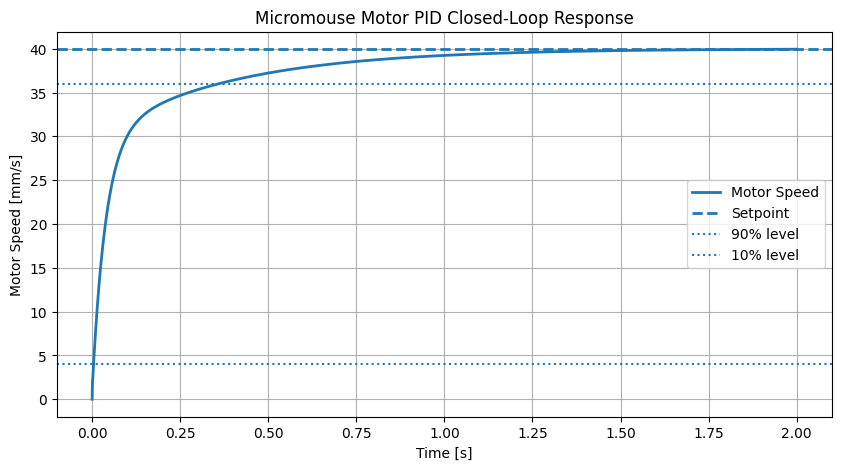

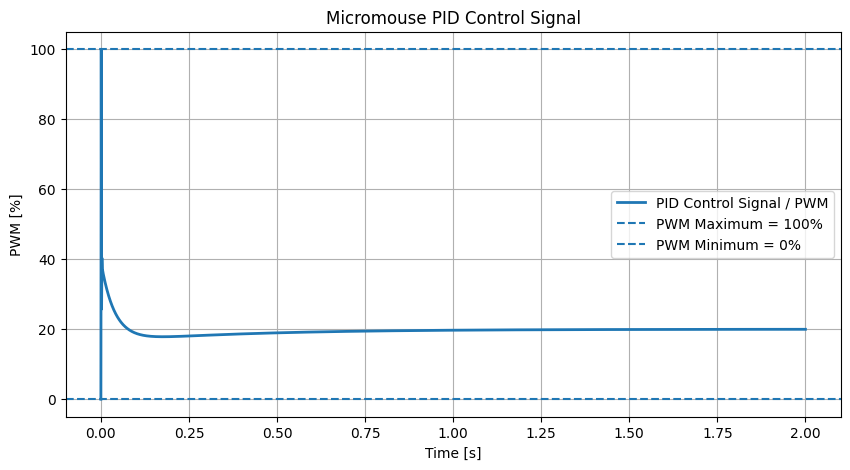


OPEN-LOOP MOTOR MODEL CHECK
Test PWM              = 30.00 %
Expected final speed  = 60.00 mm/s
63.2% speed           = 37.92 mm/s
Estimated tau         = 0.1000 s


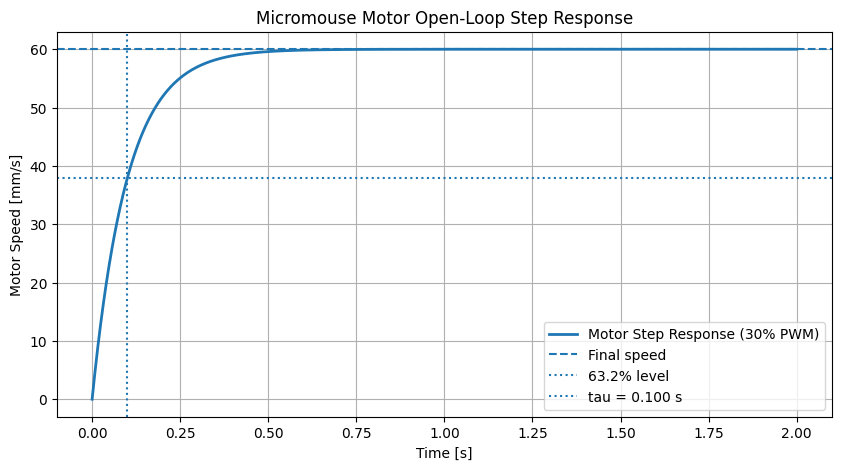


MY SYSTEM - PROJECT APPLICATION SUMMARY

Plant:
Micromouse DC drive motor.

Motor driver:
TB6612FNG dual DC motor driver.

Control input:
PWM duty cycle from 0% to 100%.

Feedback:
Motor speed measured using encoder.

Control strategy:
PID speed control.

Plant model:
G(s) = K / (tau*s + 1)

Numerical method:
Euler integration.

Controller:
u = Kp*e + Ki*integral(e) + Kd*de/dt

Project objective:
Track the desired motor speed while reducing
steady-state error and controlling overshoot.

K  = 2.0000
tau = 0.1000 s

Final PID:
Kp = 1.2000
Ki = 4.0000
Kd = 0.0100

Final simulated performance:
Rise time          = 0.3540 s
Overshoot          = 0.00 %
Settling time      = 0.9820 s
Steady-state error = 0.0574 mm/s


In [1]:
# ============================================================
# ENCS4380 - Micromouse PID Motor Control
# Project Application + Validation
# File: micromouse_motor_pid.py
#
# Model:
#     G(s) = K / (tau*s + 1)
#
# PID:
#     u = Kp*e + Ki*integral(e) + Kd*de/dt
#
# Numerical solver:
#     Euler method
# ============================================================

import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# 1. MOTOR MODEL PARAMETERS
# ============================================================

# IMPORTANT:
# These are PLACEHOLDER model parameters for simulation.
# They must be replaced by the K and tau obtained from
# the real Micromouse motor + encoder step-response test.

K = 2.0          # Motor steady-state gain
tau = 0.10       # Motor time constant [s]

# Motor input is PWM percentage: 0 -> 100%
PWM_MAX = 100.0
PWM_MIN = 0.0

# Desired motor speed
SETPOINT = 40.0      # mm/s


# ============================================================
# 2. SIMULATION SETTINGS
# ============================================================

dt = 0.001           # Euler simulation step [s]
T_END = 2.0          # Simulation time [s]

t = np.arange(0, T_END + dt, dt)
N = len(t)


# ============================================================
# 3. PID GAINS
# ============================================================

# Starting PID gains.
# These can be tuned after obtaining the real K and tau.

Kp = 1.20
Ki = 4.00
Kd = 0.01


# ============================================================
# 4. FIRST-ORDER MOTOR MODEL
# ============================================================

# Continuous-time model:
#
#       K
# G = -------
#     tau*s + 1
#
# Differential equation:
#
# tau * dy/dt + y = K*u
#
# Therefore:
#
# dy/dt = (K*u - y) / tau


def motor_derivative(y, u):
    return (K * u - y) / tau


# ============================================================
# 5. PID SIMULATION
# ============================================================

y = np.zeros(N)              # Motor speed
u = np.zeros(N)              # Control signal / PWM
e = np.zeros(N)              # Error
integral = 0.0

previous_error = 0.0

for k in range(1, N):

    # Error
    e[k] = SETPOINT - y[k-1]

    # Integral term
    integral += e[k] * dt

    # Derivative term
    derivative = (e[k] - previous_error) / dt

    # PID equation
    u_unsaturated = (
        Kp * e[k]
        + Ki * integral
        + Kd * derivative
    )

    # PWM saturation: 0% to 100%
    u[k] = np.clip(
        u_unsaturated,
        PWM_MIN,
        PWM_MAX
    )

    # Anti-windup
    # If the actuator is saturated, prevent the integral
    # from continuing to grow in the wrong direction.

    if u[k] != u_unsaturated:

        integral -= e[k] * dt

        u_unsaturated = (
            Kp * e[k]
            + Ki * integral
            + Kd * derivative
        )

        u[k] = np.clip(
            u_unsaturated,
            PWM_MIN,
            PWM_MAX
        )

    # Euler integration
    dy = motor_derivative(y[k-1], u[k])

    y[k] = y[k-1] + dy * dt

    previous_error = e[k]


# ============================================================
# 6. PERFORMANCE METRICS
# ============================================================

final_value = y[-1]

steady_state_error = abs(
    SETPOINT - final_value
)

# Rise time: 10% -> 90%
y10 = 0.10 * SETPOINT
y90 = 0.90 * SETPOINT

idx10 = np.where(y >= y10)[0]
idx90 = np.where(y >= y90)[0]

if len(idx10) > 0 and len(idx90) > 0:

    t10 = t[idx10[0]]
    t90 = t[idx90[0]]

    rise_time = t90 - t10

else:
    rise_time = np.nan


# Overshoot
peak_value = np.max(y)

if SETPOINT != 0:
    overshoot = max(
        0.0,
        (peak_value - SETPOINT)
        / SETPOINT * 100
    )
else:
    overshoot = 0.0


# Settling time: ±2%
upper_limit = SETPOINT * 1.02
lower_limit = SETPOINT * 0.98

outside = np.where(
    (y > upper_limit) |
    (y < lower_limit)
)[0]

if len(outside) == 0:

    settling_time = 0.0

else:

    last_outside = outside[-1]

    if last_outside < N - 1:
        settling_time = t[last_outside + 1]
    else:
        settling_time = np.nan


# ============================================================
# 7. PWM CHECK
# ============================================================

pwm_ok = (
    np.all(u >= PWM_MIN) and
    np.all(u <= PWM_MAX)
)


# ============================================================
# 8. PRINT RESULTS
# ============================================================

print("=" * 60)
print("MICROMOUSE MOTOR PID CONTROL")
print("=" * 60)

print("\nMotor Model:")
print(f"K       = {K:.4f}")
print(f"tau     = {tau:.4f} s")

print("\nPID Gains:")
print(f"Kp      = {Kp:.4f}")
print(f"Ki      = {Ki:.4f}")
print(f"Kd      = {Kd:.4f}")

print("\nReference:")
print(f"Setpoint = {SETPOINT:.2f} mm/s")

print("\nPerformance:")
print(f"Final speed          = {final_value:.4f} mm/s")
print(f"Rise time            = {rise_time:.4f} s")
print(f"Overshoot            = {overshoot:.2f} %")
print(f"Settling time        = {settling_time:.4f} s")
print(f"Steady-state error   = {steady_state_error:.4f} mm/s")

print("\nPWM:")
print(f"Minimum PWM          = {np.min(u):.2f} %")
print(f"Maximum PWM          = {np.max(u):.2f} %")
print(f"PWM constraint       = {'PASS' if pwm_ok else 'FAIL'}")

print("\nController:")
print("PID simulation       = PASS")
print("Euler solver         = PASS")

print("=" * 60)


# ============================================================
# 9. RESPONSE PLOT
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    t,
    y,
    linewidth=2,
    label="Motor Speed"
)

plt.axhline(
    SETPOINT,
    linestyle="--",
    linewidth=2,
    label="Setpoint"
)

plt.axhline(
    y90,
    linestyle=":",
    linewidth=1.5,
    label="90% level"
)

plt.axhline(
    y10,
    linestyle=":",
    linewidth=1.5,
    label="10% level"
)

plt.xlabel("Time [s]")
plt.ylabel("Motor Speed [mm/s]")

plt.title(
    "Micromouse Motor PID Closed-Loop Response"
)

plt.grid(True)
plt.legend()

plt.show()


# ============================================================
# 10. CONTROL SIGNAL / PWM PLOT
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    t,
    u,
    linewidth=2,
    label="PID Control Signal / PWM"
)

plt.axhline(
    PWM_MAX,
    linestyle="--",
    linewidth=1.5,
    label="PWM Maximum = 100%"
)

plt.axhline(
    PWM_MIN,
    linestyle="--",
    linewidth=1.5,
    label="PWM Minimum = 0%"
)

plt.xlabel("Time [s]")
plt.ylabel("PWM [%]")

plt.title(
    "Micromouse PID Control Signal"
)

plt.ylim(-5, 105)

plt.grid(True)
plt.legend()

plt.show()


# ============================================================
# 11. FIRST-ORDER MOTOR STEP RESPONSE
# ============================================================

# Open-loop response for comparison:
#
# y(t) = K*u*(1 - exp(-t/tau))

PWM_TEST = 30.0

y_step = (
    K * PWM_TEST *
    (1 - np.exp(-t / tau))
)

final_step_speed = K * PWM_TEST

target_632 = 0.632 * final_step_speed

idx_tau = np.argmin(
    np.abs(y_step - target_632)
)

measured_tau_from_model = t[idx_tau]


print("\n" + "=" * 60)
print("OPEN-LOOP MOTOR MODEL CHECK")
print("=" * 60)

print(f"Test PWM              = {PWM_TEST:.2f} %")
print(f"Expected final speed  = {final_step_speed:.2f} mm/s")
print(f"63.2% speed           = {target_632:.2f} mm/s")
print(
    f"Estimated tau         = "
    f"{measured_tau_from_model:.4f} s"
)

print("=" * 60)


plt.figure(figsize=(10, 5))

plt.plot(
    t,
    y_step,
    linewidth=2,
    label=f"Motor Step Response ({PWM_TEST:.0f}% PWM)"
)

plt.axhline(
    final_step_speed,
    linestyle="--",
    linewidth=1.5,
    label="Final speed"
)

plt.axhline(
    target_632,
    linestyle=":",
    linewidth=1.5,
    label="63.2% level"
)

plt.axvline(
    measured_tau_from_model,
    linestyle=":",
    linewidth=1.5,
    label=f"tau = {measured_tau_from_model:.3f} s"
)

plt.xlabel("Time [s]")
plt.ylabel("Motor Speed [mm/s]")

plt.title(
    "Micromouse Motor Open-Loop Step Response"
)

plt.grid(True)
plt.legend()

plt.show()


# ============================================================
# 12. PROJECT APPLICATION SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("MY SYSTEM - PROJECT APPLICATION SUMMARY")
print("=" * 60)

print("""
Plant:
Micromouse DC drive motor.

Motor driver:
TB6612FNG dual DC motor driver.

Control input:
PWM duty cycle from 0% to 100%.

Feedback:
Motor speed measured using encoder.

Control strategy:
PID speed control.

Plant model:
G(s) = K / (tau*s + 1)

Numerical method:
Euler integration.

Controller:
u = Kp*e + Ki*integral(e) + Kd*de/dt

Project objective:
Track the desired motor speed while reducing
steady-state error and controlling overshoot.
""")

print(f"K  = {K:.4f}")
print(f"tau = {tau:.4f} s")

print("\nFinal PID:")
print(f"Kp = {Kp:.4f}")
print(f"Ki = {Ki:.4f}")
print(f"Kd = {Kd:.4f}")

print("\nFinal simulated performance:")
print(f"Rise time          = {rise_time:.4f} s")
print(f"Overshoot          = {overshoot:.2f} %")
print(f"Settling time      = {settling_time:.4f} s")
print(f"Steady-state error = {steady_state_error:.4f} mm/s")

print("=" * 60)